In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.ndimage import generic_filter

from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import KFold, GroupKFold, LeaveOneGroupOut, RandomizedSearchCV, cross_val_predict
from sklearn.metrics import r2_score, root_mean_squared_error

# Tworzenie katalogów wynikowych
os.makedirs("../results/tables", exist_ok=True)
os.makedirs("../results/figures", exist_ok=True)
os.makedirs("../results/models", exist_ok=True)

# 1. Wczytanie bazy danych z upscalingu
csv_path = "../results/tables/baza_kalibracyjna_UAV_PlanetScope_FVC.csv"
df = pd.read_csv(csv_path)
print(f"Początkowa liczba wierszy: {len(df)}")

# 2. Naprawa ewentualnych literówek w nazwach pól ('O1W' -> '01W')
df['field_id'] = df['field_id'].astype(str).str.strip().replace({'O1W': '01W', 'O2W': '02W'})
df['flight_date'] = df['flight_date'].astype(str).str.strip()

# 3. Odfiltrowanie wartości NaN / Inf oraz anomalii poza zakresem fizycznym
df = df.replace([np.inf, -np.inf], np.nan).dropna().copy()

norm_indices = ['NDVI', 'SAVI', 'RENDVI', 'NDWI']
for idx in norm_indices:
    for prefix in ['UAV_', 'PS_']:
        col = f"{prefix}{idx}"
        if col in df.columns:
            df = df[df[col].between(-1.0, 1.0)]

df = df[df['UAV_EVI'].between(-1.0, 3.0) & df['PS_EVI'].between(-1.0, 3.0)]
df = df[df['UAV_CIre'].between(-1.0, 15.0) & df['PS_CIre'].between(-1.0, 15.0)]
df = df.reset_index(drop=True)

# 4. Generowanie szachownicy przestrzennej (Block_ID 30x30 m)
BLOCK_SIZE = 30.0
block_x = (df['x_center'] // BLOCK_SIZE).astype(int)
block_y = (df['y_center'] // BLOCK_SIZE).astype(int)
df['Block_ID'] = df['field_id'] + "_" + block_x.astype(str) + "_" + block_y.astype(str)

print(f"Liczba wierszy po oczyszczeniu: {len(df)}")
print(f"Pola w bazie: {df['field_id'].unique()} | Terminy nalotów ({df['flight_date'].nunique()}): {sorted(df['flight_date'].unique())}")
print(f"Utworzono {df['Block_ID'].nunique()} unikalnych bloków przestrzennych 30x30 m.")

Początkowa liczba wierszy: 18465
Liczba wierszy po oczyszczeniu: 18460
Pola w bazie: <StringArray>
['01W']
Length: 1, dtype: str | Terminy nalotów (7): ['2026-08-10', '2026-09-02', '2026-09-09', '2026-09-15', '2026-10-01', '2026-10-03', '2026-10-06']
Utworzono 59 unikalnych bloków przestrzennych 30x30 m.


In [5]:
# ==============================================================================
# DIAGNOSTYKA RADIOMETRYCZNA PER TERMIN (ŚREDNIE WARTOŚCI ORAZ BIAS: PS - UAV)
# ==============================================================================
TARGETS_6 = ['UAV_NDVI', 'UAV_SAVI', 'UAV_EVI', 'UAV_RENDVI', 'UAV_CIre', 'UAV_NDWI']
INDICES_6 = ['NDVI', 'SAVI', 'EVI', 'RENDVI', 'CIre', 'NDWI']

diag_rows = []
for (fid, dt), grp in df.groupby(['field_id', 'flight_date']):
    row_d = {'field_id': fid, 'flight_date': dt, 'n_pixels': len(grp), 'FVC_mean': round(grp['FVC'].mean(), 3)}
    for idx in ['NDVI', 'SAVI', 'EVI', 'RENDVI', 'NDWI']:
        uav_m = grp[f'UAV_{idx}'].mean()
        ps_m  = grp[f'PS_{idx}'].mean()
        r_corr = np.corrcoef(grp[f'UAV_{idx}'], grp[f'PS_{idx}'])[0, 1]
        row_d[f'UAV_{idx}'] = round(uav_m, 3)
        row_d[f'PS_{idx}']  = round(ps_m, 3)
        row_d[f'Bias_{idx} (PS-UAV)'] = round(ps_m - uav_m, 3)
        row_d[f'r_{idx}'] = round(r_corr, 2)
    diag_rows.append(row_d)

df_diag = pd.DataFrame(diag_rows)
df_diag.to_csv("../results/tables/diagnostyka_radiometryczna_bias_per_termin.csv", index=False)
print("=== DIAGNOSTYKA RADIOMETRYCZNA (ŚREDNIE, BIAS PS-UAV ORAZ KORELACJA PER TERMIN) ===")
display(df_diag)

# Sprawdzenie średnich wartości surowych pasm PlanetScope w poszczególnych terminach
ps_raw_cols = [c for c in ['PS_Blue', 'PS_Green', 'PS_Red', 'PS_RedEdge', 'PS_NIR'] if c in df.columns]
if ps_raw_cols:
    print("\n=== ŚREDNIA REFLEKTANCJA SUROWYCH PASM PLANETSCOPE PER TERMIN ===")
    display(df.groupby(['field_id', 'flight_date'])[ps_raw_cols].mean().round(4))

=== DIAGNOSTYKA RADIOMETRYCZNA (ŚREDNIE, BIAS PS-UAV ORAZ KORELACJA PER TERMIN) ===


,field_id,flight_date,n_pixels,FVC_mean,UAV_NDVI,PS_NDVI,Bias_NDVI (PS-UAV),r_NDVI,UAV_SAVI,PS_SAVI,...,Bias_EVI (PS-UAV),r_EVI,UAV_RENDVI,PS_RENDVI,Bias_RENDVI (PS-UAV),r_RENDVI,UAV_NDWI,PS_NDWI,Bias_NDWI (PS-UAV),r_NDWI
0,01W,2026-08-10,3685,0.960,0.584,0.771,0.187,0.45,0.405,0.569,...,0.215,0.59,0.326,0.501,0.174,0.47,-0.056,-0.680,-0.624,0.66
1,01W,2026-09-02,2859,0.969,0.580,0.724,0.144,0.76,0.407,0.508,...,0.145,0.59,0.347,0.492,0.144,0.77,-0.047,-0.642,-0.595,0.78
2,01W,2026-09-09,2422,0.960,0.522,0.721,0.199,0.76,0.364,0.520,...,0.185,0.56,0.306,0.468,0.162,0.77,-0.007,-0.655,-0.648,0.77
3,01W,2026-09-15,2715,0.964,0.466,0.723,0.257,0.68,0.335,0.481,...,0.175,0.57,0.291,0.462,0.172,0.76,0.078,-0.639,-0.717,0.75
4,01W,2026-10-01,2705,0.914,0.438,0.722,0.284,0.74,0.318,0.481,...,0.197,0.53,0.253,0.456,0.203,0.75,0.049,-0.649,-0.698,0.79
5,01W,2026-10-03,2703,0.952,0.411,0.714,0.303,0.73,0.292,0.491,...,0.251,0.56,0.233,0.446,0.213,0.75,0.063,-0.642,-0.705,0.78
6,01W,2026-10-06,1371,0.910,0.437,0.716,0.279,0.76,0.319,0.477,...,0.170,0.50,0.262,0.481,0.219,0.84,0.032,-0.674,-0.706,0.83



=== ŚREDNIA REFLEKTANCJA SUROWYCH PASM PLANETSCOPE PER TERMIN ===


PS_Blue  PS_Green  PS_Red  PS_RedEdge  PS_NIR
field_id flight_date                                               
01W      2026-08-10    0.0379    0.0815  0.0551      0.1422  0.4293
         2026-09-02    0.0420    0.0820  0.0599      0.1282  0.3779
         2026-09-09    0.0343    0.0827  0.0642      0.1439  0.3982
         2026-09-15    0.0357    0.0752  0.0547      0.1257  0.3440
         2026-10-01    0.0343    0.0730  0.0551      0.1283  0.3442
         2026-10-03    0.0386    0.0787  0.0603      0.1385  0.3629
         2026-10-06    0.0269    0.0669  0.0567      0.1203  0.3432

In [2]:
# ==============================================================================
# INŻYNIERIA CECH: OKNO SĄSIEDZTWA 3x3 (9x9m), INTERAKCJE GLEBOWE I Z-SCORE
# ==============================================================================
df_clean = df.copy()

def add_spatial_3x3_features(dataframe, cols_to_filter):
    """Odtwarza siatkę 2D dla każdego pola/daty i wylicza średnią, odchylenie std (teksturę)
    oraz odchyłkę centralnego piksela od otoczenia 3x3 pikseli PlanetScope (9x9 m)."""
    for col in cols_to_filter:
        dataframe[f'{col}_mean3x3'] = np.nan
        dataframe[f'{col}_std3x3']  = np.nan
        dataframe[f'{col}_diff3x3'] = np.nan

    for (fid, dt), group in dataframe.groupby(['field_id', 'flight_date']):
        r_min, r_max = int(group['row'].min()), int(group['row'].max())
        c_min, c_max = int(group['col'].min()), int(group['col'].max())
        shape = (r_max - r_min + 1, c_max - c_min + 1)
        
        r_idx = group['row'].astype(int).values - r_min
        c_idx = group['col'].astype(int).values - c_min
        
        for col in cols_to_filter:
            grid = np.full(shape, np.nan)
            grid[r_idx, c_idx] = group[col].values
            
            mean_3x3 = generic_filter(grid, np.nanmean, size=3, mode='constant', cval=np.nan)
            std_3x3  = generic_filter(grid, np.nanstd,  size=3, mode='constant', cval=np.nan)
            
            dataframe.loc[group.index, f'{col}_mean3x3'] = mean_3x3[r_idx, c_idx]
            dataframe.loc[group.index, f'{col}_std3x3']  = std_3x3[r_idx, c_idx]
            dataframe.loc[group.index, f'{col}_diff3x3'] = grid[r_idx, c_idx] - mean_3x3[r_idx, c_idx]
            
    return dataframe.fillna(0)

print("Wyliczanie cech sąsiedztwa przestrzennego 3x3 (okno 9x9 m)...")
SPATIAL_COLS = ['PS_NDVI', 'PS_RENDVI', 'PS_SAVI', 'PS_NDWI', 'PS_NIR']
df_clean = add_spatial_3x3_features(df_clean, SPATIAL_COLS)

# Zgodnie z analizą: usuwamy PS_CIre ze zbioru cech wejściowych X (tożsamość rangowa z PS_RENDVI: RENDVI = CIre/(CIre+2))
PS_IND_5     = ['PS_NDVI', 'PS_SAVI', 'PS_EVI', 'PS_RENDVI', 'PS_NDWI']
PS_RAW_BANDS = [c for c in ['PS_Blue', 'PS_Green', 'PS_Red', 'PS_RedEdge', 'PS_NIR'] if c in df_clean.columns]

# Cechy interakcji glebowo-roślinnych
df_clean['PS_soil_diff']  = df_clean['PS_NDVI'] - df_clean['PS_SAVI']
df_clean['PS_soil_ratio'] = df_clean['PS_SAVI'] / (df_clean['PS_NDVI'] + 1e-6)
df_clean['PS_re_ratio']   = df_clean['PS_RENDVI'] / (df_clean['PS_NDVI'] + 1e-6)
INTERACTION_COLS = ['PS_soil_diff', 'PS_soil_ratio', 'PS_re_ratio']

# Cechy Z-score wewnątrz terminu
ZSCORE_COLS = []
for col in PS_IND_5:
    m = df_clean.groupby(['field_id', 'flight_date'])[col].transform('mean')
    s = df_clean.groupby(['field_id', 'flight_date'])[col].transform('std')
    z_col = f'{col}_zscore'
    df_clean[z_col] = (df_clean[col] - m) / (s + 1e-6)
    ZSCORE_COLS.append(z_col)

NEIGHBOR_3X3_COLS = (
    [f'{c}_mean3x3' for c in SPATIAL_COLS] + 
    [f'{c}_std3x3'  for c in SPATIAL_COLS] + 
    [f'{c}_diff3x3' for c in SPATIAL_COLS]
)

groups_block = df_clean['Block_ID'].values
groups_time  = df_clean['flight_date'].values

print(f"Gotowe! Wygenerowano {len(NEIGHBOR_3X3_COLS)} cech sąsiedztwa 3x3.")

Wyliczanie cech sąsiedztwa przestrzennego 3x3 (okno 9x9 m)...


c:\Users\user\miniconda3\envs\inzynierka2\Lib\site-packages\scipy\ndimage\_filters.py:2420: RuntimeWarning: Mean of empty slice
  _nd_image.generic_filter(input, function, footprint, output, mode,
c:\Users\user\miniconda3\envs\inzynierka2\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
c:\Users\user\miniconda3\envs\inzynierka2\Lib\site-packages\scipy\ndimage\_filters.py:2420: RuntimeWarning: Mean of empty slice
  _nd_image.generic_filter(input, function, footprint, output, mode,
c:\Users\user\miniconda3\envs\inzynierka2\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
c:\Users\user\miniconda3\envs\inzynierka2\Lib\site-packages\scipy\ndimage\_filters.py:2420: RuntimeWarning: Mean of empty slice
  _nd_image.generic_filter(input, function, footprint, o

Gotowe! Wygenerowano 15 cech sąsiedztwa 3x3.


In [3]:
# ==============================================================================
# 1. DEFINICJA ZESTAWÓW CECH DO BADANIA ABLACJI (ABLATION STUDY)
# ==============================================================================
ablation_sets = {
    '1. Bazowe (5 wsk. bez CIre)': PS_IND_5,
    '2. + Surowe pasma (5 pasm)': PS_IND_5 + PS_RAW_BANDS,
    '3. + Interakcje glebowe': PS_IND_5 + PS_RAW_BANDS + INTERACTION_COLS,
    '4. + Sąsiedztwo 3x3 (bez Z-score)': PS_IND_5 + PS_RAW_BANDS + INTERACTION_COLS + NEIGHBOR_3X3_COLS,
    '5. Pełny satelitarny (+3x3 +Z-score)': PS_IND_5 + PS_RAW_BANDS + INTERACTION_COLS + NEIGHBOR_3X3_COLS + ZSCORE_COLS,
    '6. Górna granica referencyjna (+FVC)': PS_IND_5 + PS_RAW_BANDS + INTERACTION_COLS + NEIGHBOR_3X3_COLS + ['FVC']
}

cv_random = KFold(n_splits=5, shuffle=True, random_state=42)
cv_block  = GroupKFold(n_splits=5)
cv_time   = LeaveOneGroupOut()

# ==============================================================================
# 2. SZYBKI TUNING HIPERPARAMETRÓW NA WALIDACJI BLOKOWEJ 30x30m
# ==============================================================================
X_tune = df_clean[ablation_sets['4. + Sąsiedztwo 3x3 (bez Z-score)']].values
y_tune = df_clean['UAV_NDVI'].values - df_clean['PS_NDVI'].values

param_dist = {
    'n_estimators': [150, 200, 300],
    'max_depth': [8, 10, 12, 15],
    'min_samples_leaf': [6, 8, 12, 16],
    'min_samples_split': [5, 10, 20],
    'max_features': ['sqrt', 0.5, 0.7]
}

print("Strojenie hiperparametrów Random Forest (Spatial RandomizedSearchCV)...")
search = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=42, n_jobs=-1),
    param_distributions=param_dist,
    n_iter=10,
    scoring='r2',
    cv=cv_block,
    random_state=42,
    n_jobs=-1
)
search.fit(X_tune, y_tune, groups=groups_block)
best_rf_params = {**search.best_params_, 'random_state': 42, 'n_jobs': -1}
print(f" -> Wyłonione parametry RF: {best_rf_params}\n")

# ==============================================================================
# 3. URUCHOMIENIE TESTU ABLACJI: CEL BEZPOŚREDNI (UAV) vs RÓŻNICA (UAV - PS)
# ==============================================================================
rf_abl = RandomForestRegressor(**best_rf_params)
ablation_results = []

print("Wykonywanie badania ablacji w walidacji blokowej 30x30m...")
for set_name, feat_list in ablation_sets.items():
    X_sub = df_clean[feat_list].values
    row_res = {'Konfiguracja cech (Ablacja)': set_name, 'Liczba cech': len(feat_list)}
    
    for t_idx in ['NDVI', 'SAVI', 'RENDVI', 'NDWI']:
        y_true = df_clean[f'UAV_{t_idx}'].values
        y_ps   = df_clean[f'PS_{t_idx}'].values
        y_res  = y_true - y_ps  # Cel jako różnica UAV - PS
        
        pred_direct = cross_val_predict(rf_abl, X_sub, y_true, cv=cv_block, groups=groups_block, n_jobs=-1)
        pred_res    = y_ps + cross_val_predict(rf_abl, X_sub, y_res, cv=cv_block, groups=groups_block, n_jobs=-1)
        
        row_res[f'{t_idx} R2 (Bezpośr.)'] = round(r2_score(y_true, pred_direct), 3)
        row_res[f'{t_idx} R2 (Różnica UAV-PS)'] = round(r2_score(y_true, pred_res), 3)
        
    ablation_results.append(row_res)

df_ablacja = pd.DataFrame(ablation_results)
df_ablacja.to_csv("../results/tables/analiza_ablacji_cech.csv", index=False)
print("=== WYNIKI BADANIA ABLACJI ORAZ PORÓWNANIE CELU BEZPOŚREDNIEGO Z RÓŻNICOWYM (UAV - PS) ===")
display(df_ablacja)

Strojenie hiperparametrów Random Forest (Spatial RandomizedSearchCV)...
 -> Wyłonione parametry RF: {'n_estimators': 150, 'min_samples_split': 5, 'min_samples_leaf': 6, 'max_features': 0.7, 'max_depth': 10, 'random_state': 42, 'n_jobs': -1}

Wykonywanie badania ablacji w walidacji blokowej 30x30m...
=== WYNIKI BADANIA ABLACJI ORAZ PORÓWNANIE CELU BEZPOŚREDNIEGO Z RÓŻNICOWYM (UAV - PS) ===


,Konfiguracja cech (Ablacja),Liczba cech,NDVI R2 (Bezpośr.),NDVI R2 (Różnica UAV-PS),SAVI R2 (Bezpośr.),SAVI R2 (Różnica UAV-PS),RENDVI R2 (Bezpośr.),RENDVI R2 (Różnica UAV-PS),NDWI R2 (Bezpośr.),NDWI R2 (Różnica UAV-PS)
0,1. Bazowe (5 wsk. bez CIre),5,0.672,0.670,0.423,0.425,0.563,0.562,0.679,0.683
1,2. + Surowe pasma (5 pasm),10,0.673,0.673,0.423,0.423,0.568,0.573,0.683,0.684
2,3. + Interakcje glebowe,13,0.677,0.677,0.422,0.421,0.569,0.571,0.686,0.689
3,4. + Sąsiedztwo 3x3 (bez Z-score),28,0.717,0.723,0.451,0.460,0.631,0.635,0.719,0.723
4,5. Pełny satelitarny (+3x3 +Z-score),33,0.718,0.724,0.450,0.460,0.634,0.640,0.716,0.723
5,6. Górna granica referencyjna (+FVC),29,0.859,0.859,0.539,0.542,0.753,0.748,0.800,0.806


In [6]:
# ==============================================================================
# FINALNA WALIDACJA DLA 6 WSKAŹNIKÓW Z METRYKAMI nRMSE (%) ORAZ ANALIZĄ BIASU LODO
# ==============================================================================
# Możesz wybrać zestaw 4 (bez Z-score) lub 5 (z Z-score) w zależności od wyniku z tabeli ablacji:
FINAL_FEATURES = ablation_sets['5. Pełny satelitarny (+3x3 +Z-score)']
REF_FVC_FEATURES = ablation_sets['6. Górna granica referencyjna (+FVC)']

X_final   = df_clean[FINAL_FEATURES].values
X_ref_fvc = df_clean[REF_FVC_FEATURES].values

final_metrics = []
lodo_bias_rows = []

for idx_name in INDICES_6:
    target = f'UAV_{idx_name}'
    ps_col = f'PS_{idx_name}'
    
    y_true = df_clean[target].values
    y_ps   = df_clean[ps_col].values
    y_res  = y_true - y_ps  # Modelujemy różnicę UAV - PS
    
    rf_model = RandomForestRegressor(**best_rf_params)
    
    # 1. Walidacja Losowa K-Fold
    pred_rand = y_ps + cross_val_predict(rf_model, X_final, y_res, cv=cv_random, n_jobs=-1)
    
    # 2. Walidacja Blokowa 30x30m (Główny model wdrożeniowy)
    pred_block = y_ps + cross_val_predict(rf_model, X_final, y_res, cv=cv_block, groups=groups_block, n_jobs=-1)
    df_clean[f'Pred_{target}'] = pred_block
    
    # 3. Górna granica referencyjna z udziałem FVC
    pred_fvc = y_ps + cross_val_predict(rf_model, X_ref_fvc, y_res, cv=cv_block, groups=groups_block, n_jobs=-1)
    
    # 4. Walidacja Czasowa LODO (Leave-One-Date-Out)
    pred_time = y_ps + cross_val_predict(rf_model, X_final, y_res, cv=cv_time, groups=groups_time, n_jobs=-1)
    
    # Obliczenie metryk błędu bezwzględnego i znormalizowanego (nRMSE względem odch. std. oraz zakresu P98-P02)
    rmse_blk = root_mean_squared_error(y_true, pred_block)
    std_y    = np.std(y_true)
    iqr_96   = np.percentile(y_true, 98) - np.percentile(y_true, 2)
    
    nrmse_std_pct   = (rmse_blk / std_y) * 100.0
    nrmse_range_pct = (rmse_blk / iqr_96) * 100.0
    
    r2_time_per_day = []
    for dt in sorted(np.unique(groups_time)):
        mask_dt = (groups_time == dt)
        r2_dt = np.corrcoef(y_true[mask_dt], pred_time[mask_dt])[0, 1] ** 2
        bias_dt = np.mean(pred_time[mask_dt] - y_true[mask_dt])
        r2_time_per_day.append(r2_dt)
        if idx_name in ['NDVI', 'RENDVI', 'SAVI']:
            lodo_bias_rows.append({
                'Wskaźnik': target, 'Data_testowa (LODO)': dt,
                'R2_Wewnątrz_Dnia': round(r2_dt, 3),
                'Bias_LODO (Pred - UAV)': round(bias_dt, 3),
                'RMSE_Dnia': round(root_mean_squared_error(y_true[mask_dt], pred_time[mask_dt]), 3)
            })
            
    final_metrics.append({
        'Wskaźnik': target,
        'R2_Losowa': round(r2_score(y_true, pred_rand), 3),
        'R2_Blokowa (30x30m)': round(r2_score(y_true, pred_block), 3),
        'R2_Górny_Pułap (z FVC)': round(r2_score(y_true, pred_fvc), 3),
        'RMSE_Blokowa': round(rmse_blk, 3),
        'nRMSE (% zakresu)': round(nrmse_range_pct, 1),
        'nRMSE (% std)': round(nrmse_std_pct, 1),
        'R2_Czasowa (Wzorzec)': round(np.mean(r2_time_per_day), 3),
        'R2_Czasowa (Zbiorcza)': round(r2_score(y_true, pred_time), 3),
        'RMSE_Czasowa': round(root_mean_squared_error(y_true, pred_time), 3)
    })

df_final_metrics = pd.DataFrame(final_metrics)
df_final_metrics.to_csv("../results/tables/finalne_wyniki_walidacji_nRMSE.csv", index=False)
print("=== FINALNA TABELA WYNIKÓW WALIDACJI (SĄSIEDZTWO 3x3 + PREDYKCJA RÓŻNICOWA + nRMSE) ===")
display(df_final_metrics)

df_lodo_bias = pd.DataFrame(lodo_bias_rows)
df_lodo_bias.to_csv("../results/tables/diagnostyka_LODO_bias_per_data.csv", index=False)
print("\n=== DIAGNOSTYKA WALIDACJI CZASOWEJ (LODO): BIAS I R2 PER DATA ===")
display(df_lodo_bias.pivot(index='Data_testowa (LODO)', columns='Wskaźnik', values=['R2_Wewnątrz_Dnia', 'Bias_LODO (Pred - UAV)']))

=== FINALNA TABELA WYNIKÓW WALIDACJI (SĄSIEDZTWO 3x3 + PREDYKCJA RÓŻNICOWA + nRMSE) ===


,Wskaźnik,R2_Losowa,R2_Blokowa (30x30m),R2_Górny_Pułap (z FVC),RMSE_Blokowa,nRMSE (% zakresu),nRMSE (% std),R2_Czasowa (Wzorzec),R2_Czasowa (Zbiorcza),RMSE_Czasowa
0,UAV_NDVI,0.788,0.724,0.859,0.064,14.4,52.6,0.571,0.519,0.085
1,UAV_SAVI,0.569,0.460,0.542,0.083,18.9,73.5,0.327,0.311,0.093
2,UAV_EVI,0.585,0.472,0.551,0.095,18.6,72.6,0.329,0.323,0.108
3,UAV_RENDVI,0.725,0.640,0.748,0.051,15.2,60.0,0.543,0.430,0.064
4,UAV_CIre,0.726,0.638,0.737,0.240,14.7,60.1,0.529,0.405,0.308
5,UAV_NDWI,0.797,0.723,0.806,0.054,13.5,52.6,0.611,0.540,0.070



=== DIAGNOSTYKA WALIDACJI CZASOWEJ (LODO): BIAS I R2 PER DATA ===


R2_Wewnątrz_Dnia                      \
Wskaźnik                    UAV_NDVI UAV_RENDVI UAV_SAVI   
Data_testowa (LODO)                                        
2026-08-10                     0.450      0.287    0.424   
2026-09-02                     0.551      0.593    0.376   
2026-09-09                     0.631      0.565    0.303   
2026-09-15                     0.592      0.593    0.337   
2026-10-01                     0.632      0.595    0.317   
2026-10-03                     0.548      0.597    0.378   
2026-10-06                     0.596      0.572    0.150   

                    Bias_LODO (Pred - UAV)                      
Wskaźnik                          UAV_NDVI UAV_RENDVI UAV_SAVI  
Data_testowa (LODO)                                             
2026-08-10                           0.016      0.037    0.054  
2026-09-02                          -0.101     -0.045   -0.066  
2026-09-09                          -0.048     -0.032   -0.031  
2026-09-15                          -0.012     -0.022   -0.011  
2026-10-01                           0.001      0.013   -0.006  
2026-10-03                           0.053      0.035    0.039  
2026-10-06                           0.042      0.026   -0.018

=== ZESTAWIENIE MODELI ML (Walidacja Blokowa 30x30m) ===


,Wskaźnik,1_Ridge_R2,2_RandomForest_R2,3_GradBoosting_R2,RF_nRMSE (%),GB_nRMSE (%)
0,UAV_NDVI,0.672,0.724,0.721,14.4,14.5
1,UAV_SAVI,0.421,0.460,0.451,18.9,19.1
2,UAV_EVI,0.429,0.472,0.470,18.6,18.7
3,UAV_RENDVI,0.585,0.640,0.642,15.2,15.1
4,UAV_CIre,0.592,0.638,0.640,14.7,14.7
5,UAV_NDWI,0.677,0.723,0.725,13.5,13.4


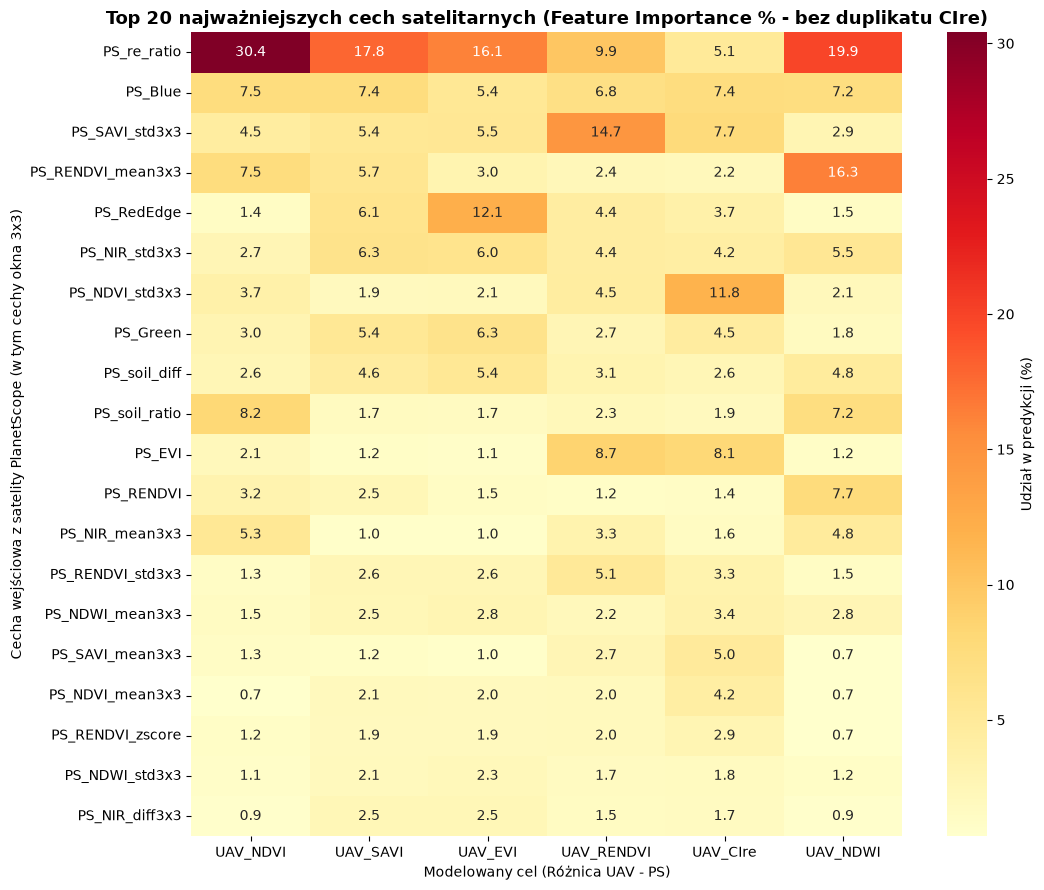

In [7]:
# ==============================================================================
# PORÓWNANIE ALGORYTMÓW ML, WYKRES FEATURE IMPORTANCE ORAZ SERIALIZACJA JOBLIB
# ==============================================================================
porownanie_alg = []
importances_dict = {}

joblib.dump(FINAL_FEATURES, "../results/models/final_features_list.joblib")

for idx_name in INDICES_6:
    target = f'UAV_{idx_name}'
    ps_col = f'PS_{idx_name}'
    
    y_true = df_clean[target].values
    y_ps   = df_clean[ps_col].values
    y_res  = y_true - y_ps
    
    # A. Regresja Liniowa Ridge (Baseline na różnicy)
    model_lin = Ridge(alpha=1.0)
    pred_lin = y_ps + cross_val_predict(model_lin, X_final, y_res, cv=cv_block, groups=groups_block)
    
    # B. Random Forest (wykorzystujemy policzone wcześniej predykcje blokowe)
    pred_rf = df_clean[f'Pred_{target}'].values
    
    # C. HistGradientBoostingRegressor (Boosting)
    model_gb = HistGradientBoostingRegressor(
        max_iter=200, max_depth=6, learning_rate=0.05, min_samples_leaf=16, random_state=42
    )
    pred_gb = y_ps + cross_val_predict(model_gb, X_final, y_res, cv=cv_block, groups=groups_block)
    
    iqr_96 = np.percentile(y_true, 98) - np.percentile(y_true, 2)
    
    porownanie_alg.append({
        'Wskaźnik': target,
        '1_Ridge_R2': round(r2_score(y_true, pred_lin), 3),
        '2_RandomForest_R2': round(r2_score(y_true, pred_rf), 3),
        '3_GradBoosting_R2': round(r2_score(y_true, pred_gb), 3),
        'RF_nRMSE (%)': round((root_mean_squared_error(y_true, pred_rf) / iqr_96) * 100.0, 1),
        'GB_nRMSE (%)': round((root_mean_squared_error(y_true, pred_gb) / iqr_96) * 100.0, 1)
    })
    
    # Trening finalnego modelu RF na całym zbiorze do analizy ważności cech i eksportu Joblib
    rf_full = RandomForestRegressor(**best_rf_params)
    rf_full.fit(X_final, y_res)
    importances_dict[target] = rf_full.feature_importances_ * 100
    
    joblib.dump(rf_full, f"../results/models/rf_residual_calibrator_{target}.joblib", compress=3)

df_alg = pd.DataFrame(porownanie_alg)
df_alg.to_csv("../results/tables/porownanie_algorytmow_ML_v2.csv", index=False)
print("=== ZESTAWIENIE MODELI ML (Walidacja Blokowa 30x30m) ===")
display(df_alg)

# Rysowanie wykresu Ważności Cech (Feature Importance) - posortowane wg średniej ważności (Top 20 cech)
df_imp = pd.DataFrame(importances_dict, index=FINAL_FEATURES)
df_imp['Mean_Imp'] = df_imp.mean(axis=1)
df_imp_sorted = df_imp.sort_values(by='Mean_Imp', ascending=False).drop(columns=['Mean_Imp']).head(20)

plt.figure(figsize=(11, 9))
sns.heatmap(df_imp_sorted, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={'label': 'Udział w predykcji (%)'})
plt.title("Top 20 najważniejszych cech satelitarnych (Feature Importance % - bez duplikatu CIre)", fontweight='bold', fontsize=13)
plt.ylabel("Cecha wejściowa z satelity PlanetScope (w tym cechy okna 3x3)")
plt.xlabel("Modelowany cel (Różnica UAV - PS)")
plt.tight_layout()
plt.savefig("../results/figures/wykres_feature_importance_RF_v2.png", dpi=300)
plt.show()

In [1]:
# ==============================================================================
# GENERATOR MAP PORÓWNAWCZYCH (SATELITA vs DRON vs PO KALIBRACJI RÓŻNICOWEJ RF)
# ==============================================================================
IDX_NAME = 'NDVI'            # Możesz zmienić np. na: 'RENDVI', 'CIre', 'SAVI', 'EVI', 'NDWI'
WYBRANA_DATA = '2026-09-15'  # Dostępne: '2026-08-10', '2026-09-02', '2026-09-09', '2026-09-15', '2026-10-01', '2026-10-03', '2026-10-06'

col_ps   = f"PS_{IDX_NAME}"
col_uav  = f"UAV_{IDX_NAME}"
col_pred = f"Pred_UAV_{IDX_NAME}"

df_date = df_clean[df_clean['flight_date'] == WYBRANA_DATA]
WYBRANE_POLE = df_date['field_id'].value_counts().index[0]
sub = df_date[df_date['field_id'] == WYBRANE_POLE].copy()

print(f"Rysowanie map -> Wskaźnik: {IDX_NAME} | Pole: {WYBRANE_POLE} | Data: {WYBRANA_DATA} | Liczba oczek 3x3m: {len(sub)}")

# Odtworzenie siatki 2D z kolumn 'row' i 'col'
r_min, r_max = int(sub['row'].min()), int(sub['row'].max())
c_min, c_max = int(sub['col'].min()), int(sub['col'].max())

shape_2d = (r_max - r_min + 1, c_max - c_min + 1)
grid_ps   = np.full(shape_2d, np.nan)
grid_uav  = np.full(shape_2d, np.nan)
grid_pred = np.full(shape_2d, np.nan)

rows_idx = sub['row'].astype(int).values - r_min
cols_idx = sub['col'].astype(int).values - c_min

grid_ps[rows_idx, cols_idx]   = sub[col_ps].values
grid_uav[rows_idx, cols_idx]  = sub[col_uav].values
grid_pred[rows_idx, cols_idx] = sub[col_pred].values

# Skale barwne (percentyle 2-98)
all_vals = np.concatenate([sub[col_ps].values, sub[col_uav].values, sub[col_pred].values])
vmin_global, vmax_global = np.nanpercentile(all_vals, 2), np.nanpercentile(all_vals, 98)

uav_vals = np.concatenate([sub[col_uav].values, sub[col_pred].values])
vmin_local, vmax_local = np.nanpercentile(uav_vals, 2), np.nanpercentile(uav_vals, 98)

fig = plt.figure(figsize=(18, 10.5))
gs = fig.add_gridspec(2, 3, height_ratios=[1.3, 1])

cmap_veg = plt.cm.RdYlGn.copy()
cmap_veg.set_bad(color='white')

# Wiersz 1: Skala globalna
titles_top = [
    f"A) Surowy PlanetScope ({col_ps})\nŚrednia: {sub[col_ps].mean():.3f} | Std: {sub[col_ps].std():.3f}",
    f"B) Referencja UAV ({col_uav})\nŚrednia: {sub[col_uav].mean():.3f} | Std: {sub[col_uav].std():.3f}",
    f"C) PlanetScope po kalibracji RF ({col_pred})\nŚrednia: {sub[col_pred].mean():.3f} | Std: {sub[col_pred].std():.3f}"
]
for i, g in enumerate([grid_ps, grid_uav, grid_pred]):
    ax = fig.add_subplot(gs[0, i])
    im = ax.imshow(g, cmap=cmap_veg, vmin=vmin_global, vmax=vmax_global)
    ax.set_title(titles_top[i], fontweight='bold', fontsize=11)
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label=f"{IDX_NAME} (skala wspólna)")

# Wiersz 2: Skala lokalna łanu + Histogram KDE
ax_uav_zoom = fig.add_subplot(gs[1, 0])
im_uz = ax_uav_zoom.imshow(grid_uav, cmap=cmap_veg, vmin=vmin_local, vmax=vmax_local)
ax_uav_zoom.set_title("D) Wzorzec przestrzenny UAV (Skala lokalna łanu)", fontweight='bold', fontsize=11)
ax_uav_zoom.axis('off')
plt.colorbar(im_uz, ax=ax_uav_zoom, fraction=0.046, pad=0.04, label=IDX_NAME)

ax_pred_zoom = fig.add_subplot(gs[1, 1])
im_pz = ax_pred_zoom.imshow(grid_pred, cmap=cmap_veg, vmin=vmin_local, vmax=vmax_local)
r_map = np.corrcoef(sub[col_uav], sub[col_pred])[0, 1]
rmse_map = np.sqrt(np.mean((sub[col_uav] - sub[col_pred]) ** 2))
ax_pred_zoom.set_title(f"E) Po kalibracji RF (Skala lokalna łanu)\nZgodność mapy: r = {r_map:.2f} | RMSE = {rmse_map:.3f}", fontweight='bold', fontsize=11)
ax_pred_zoom.axis('off')
plt.colorbar(im_pz, ax=ax_pred_zoom, fraction=0.046, pad=0.04, label=IDX_NAME)

ax_kde = fig.add_subplot(gs[1, 2])
sns.kdeplot(sub[col_ps], ax=ax_kde, color='royalblue', fill=True, alpha=0.25, linewidth=2, label='Surowy PlanetScope')
sns.kdeplot(sub[col_uav], ax=ax_kde, color='forestgreen', fill=True, alpha=0.25, linewidth=2, label='Referencja UAV (Cel)')
sns.kdeplot(sub[col_pred], ax=ax_kde, color='darkorange', linestyle='--', linewidth=2.5, label='Po kalibracji RF (Różnicowej)')
ax_kde.set_title("F) Przesunięcie rozkładu radiometrycznego pikseli", fontweight='bold', fontsize=11)
ax_kde.set_xlabel(f"Wartość wskaźnika {IDX_NAME}")
ax_kde.set_ylabel("Gęstość rozkładu (KDE)")
ax_kde.grid(True, linestyle=':', alpha=0.6)
ax_kde.legend(loc='upper left')

plt.suptitle(f"Przestrzenna kalibracja radiometryczna PlanetScope -> UAV | Wskaźnik: {IDX_NAME} | Pole: {WYBRANE_POLE} ({WYBRANA_DATA})", 
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()

out_file = f"../results/figures/mapa_kalibracja_{IDX_NAME}_{WYBRANE_POLE}_{WYBRANA_DATA}_v2.png"
plt.savefig(out_file, dpi=300, bbox_inches='tight')
plt.show()

NameError: name 'df_clean' is not defined